Feature Engineering – Betrugserkennung bei Strom und Gas
Team 5 (Roland, Leo, Tobias) · Meilenstein 3

Aus den einzelnen Rechnungen baue ich neue Features pro Kunde: Verbrauch pro Monat, Bemerkungen des Ablesers, Sprünge, Trend. Heraus kommt data/fd_features.csv, eine Zeile pro Kunde.

In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
TRAIN_DIR = DATA_DIR / "train"

STUFEN = [f"consommation_level_{i}" for i in range(1, 5)]   # Verbrauch je Tarifstufe
MAX_MONATE = 24            # längere sind Datenfehler laut EDA
REMARQUE_CODES = [6, 8, 9] # die drei häufigen Codes
TREND_TAGE = 730           # letzte 2 Jahre

# nur beim ersten Mal entpacken
if not (TRAIN_DIR / "invoice_train.csv").exists():
    with zipfile.ZipFile(DATA_DIR / "train.zip") as zf:
        zf.extractall(TRAIN_DIR)

df_invoice = pd.read_csv(TRAIN_DIR / "invoice_train.csv", dtype={"counter_statue": str})
df_cleaned = pd.read_csv(DATA_DIR / "fd_cleaned.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")

print(f"Rechnungen: {df_invoice.shape}")
print(f"Kunden:     {df_cleaned.shape}")

Rechnungen: (4476749, 16)
Kunden:     (135493, 20)


Bereinigt wie in der EDA. Den Verbrauch teile ich durch months_number, damit die Rechnungen vergleichbar sind. 0 Monate und mehr als 24 setze ich vorher auf NaN.

In [2]:
df_invoice = df_invoice.drop_duplicates().reset_index(drop=True)
df_invoice["invoice_date"] = pd.to_datetime(df_invoice["invoice_date"], format="%Y-%m-%d")
df_invoice["consumption"] = df_invoice[STUFEN].sum(axis=1)

# nur 1 bis 24 Monate, sonst NaN
monate = df_invoice["months_number"].where(df_invoice["months_number"].between(1, MAX_MONATE))
df_invoice["cons_per_month"] = df_invoice["consumption"] / monate

print(f"Rechnungen nach dem Bereinigen: {len(df_invoice):,}")
print(f"Rechnungen ohne gültige Monate: {monate.isna().sum():,} ({monate.isna().mean():.2%})")
df_invoice.groupby("counter_type")["cons_per_month"].describe().round(1)

Rechnungen nach dem Bereinigen: 4,476,738
Rechnungen ohne gültige Monate: 3,530 (0.08%)


,count,mean,std,min,25%,50%,75%,max
counter_type,,,,,,,,
ELEC,3077150.0,228.9,885.9,0.0,56.2,112.5,193.8,499836.5
GAZ,1396058.0,63.7,492.4,0.0,6.2,21.0,41.5,499955.0


Pro Kunde Median und Standardabweichung des Monatsverbrauchs, getrennt nach Strom und Gas. Dazu der Anteil der Rechnungen mit den Ablese-Codes 6, 8 und 9.

In [3]:
def monatsverbrauch(df, zaehlerart, kuerzel):
    """Median und Standardabweichung des Monatsverbrauchs pro Kunde für eine Zählerart."""
    return (
        df[df["counter_type"] == zaehlerart]
        .groupby("client_id")["cons_per_month"]
        .agg(**{f"month_median_{kuerzel}": "median", f"month_std_{kuerzel}": "std"})
    )


df_monat_strom = monatsverbrauch(df_invoice, "ELEC", "elec")
df_monat_gas = monatsverbrauch(df_invoice, "GAZ", "gaz")

# Anteil je Code
for code in REMARQUE_CODES:
    df_invoice[f"remarque_{code}"] = (df_invoice["reading_remarque"] == code).astype(int)

df_remarque = df_invoice.groupby("client_id").agg(
    **{f"share_remarque_{code}": (f"remarque_{code}", "mean") for code in REMARQUE_CODES}
)

display(df_monat_strom.head())
df_remarque.describe().round(3)

,month_median_elec,month_std_elec
client_id,,
train_Client_0,54.2500,84.545640
train_Client_1,128.5000,24.105605
train_Client_10,115.5625,45.304153
train_Client_100,0.0000,0.901753
train_Client_1000,192.5000,150.969514


,share_remarque_6,share_remarque_8,share_remarque_9
count,135493.000,135493.000,135493.000
mean,0.480,0.162,0.356
std,0.294,0.159,0.304
min,0.000,0.000,0.000
25%,0.273,0.000,0.122
50%,0.500,0.146,0.280
75%,0.667,0.250,0.500
max,1.000,1.000,1.000


Betrüger hatten in der EDA einen unruhigeren Verbrauch. Deshalb rechne ich die Änderung von einer Rechnung zur nächsten, pro Zähler, sonst gäbe ein Zählertausch einen falschen Sprung.

In [4]:
zaehler = ["client_id", "counter_number", "counter_type"]
df_invoice = df_invoice.sort_values(zaehler + ["invoice_date"])

# Änderung zur Rechnung davor
df_invoice["change"] = df_invoice.groupby(zaehler)["cons_per_month"].diff()
df_invoice["abs_change"] = df_invoice["change"].abs()

df_spruenge = df_invoice.groupby("client_id").agg(
    max_drop=("change", "min"),              # größter Rückgang
    max_rise=("change", "max"),              # größter Anstieg
    mean_abs_change=("abs_change", "mean"),
)

# Rückgang positiv. Wer nur Anstiege
# oder nur Rückgänge hatte, bekommt 0.
df_spruenge["max_drop"] = (-df_spruenge["max_drop"]).clip(lower=0)
df_spruenge["max_rise"] = df_spruenge["max_rise"].clip(lower=0)

df_spruenge.describe().round(1)

,max_drop,max_rise,mean_abs_change
count,130080.0,130080.0,130080.0
mean,344.3,343.6,93.1
std,2269.3,2647.2,398.8
min,-0.0,0.0,0.0
25%,65.8,66.8,22.3
50%,141.6,140.5,40.0
75%,280.2,277.8,77.6
max,498754.0,499836.5,46779.0


Trend ist der Verbrauch der letzten 2 Jahre geteilt durch den davor. Unter 1 heißt gesunken.

In [5]:
# Datum der letzten Rechnung je Kunde
letzte_rechnung = df_invoice.groupby("client_id")["invoice_date"].transform("max")
df_invoice["recent"] = df_invoice["invoice_date"] >= letzte_rechnung - pd.Timedelta(days=TREND_TAGE)

df_trend = pd.DataFrame({
    "cons_recent": df_invoice[df_invoice["recent"]].groupby("client_id")["cons_per_month"].mean(),
    "cons_before": df_invoice[~df_invoice["recent"]].groupby("client_id")["cons_per_month"].mean(),
})
# +1 gegen Teilen durch 0
df_trend["trend_ratio"] = (df_trend["cons_recent"] + 1) / (df_trend["cons_before"] + 1)

df_trend["trend_ratio"].describe().round(2)

count    110981.00
mean          2.80
std          41.39
min           0.00
25%           0.66
50%           0.97
75%           1.33
max        7220.10
Name: trend_ratio, dtype: float64

Alles per Left Join an fd_cleaned.csv. Der Variationskoeffizient kommt auch noch dazu.

In [6]:
df_features = df_cleaned.copy()
for tabelle in [df_monat_strom, df_monat_gas, df_remarque, df_spruenge, df_trend[["trend_ratio"]]]:
    df_features = df_features.merge(tabelle, on="client_id", how="left")

# Variationskoeffizient
for art in ["elec", "gaz"]:
    df_features[f"cv_{art}"] = df_features[f"cons_std_{art}"] / (df_features[f"cons_mean_{art}"] + 1)

neue_spalten = [spalte for spalte in df_features.columns if spalte not in df_cleaned.columns]

luecken = df_features.isna().sum()
print(f"Tabelle: {df_features.shape}, davon {len(neue_spalten)} neue Spalten")
print("\nFehlende Werte vor dem Füllen:")
print(luecken[luecken > 0])

# kein Trend -> 1, sonst 0
df_features["trend_ratio"] = df_features["trend_ratio"].fillna(1)
df_features = df_features.fillna(0)
print(f"\nFehlende Werte danach: {df_features.isna().sum().sum()}")

Tabelle: (135493, 33), davon 13 neue Spalten

Fehlende Werte vor dem Füllen:
month_median_elec      812
month_std_elec        5804
month_median_gaz     73474
month_std_gaz        75120
max_drop              5413
max_rise              5413
mean_abs_change       5413
trend_ratio          24512
dtype: int64

Fehlende Werte danach: 0


Lücken gibt es bei Kunden ohne Gas, mit nur einer Rechnung pro Zähler oder ohne Rechnung, die älter als 2 Jahre ist. trend_ratio fülle ich mit 1, den Rest mit 0.

Check auf Signal

Spearman-Korrelation mit target und Betrugsquote nach größtem Rückgang, nur im Train-Teil.

max_drop             0.146
max_rise             0.142
month_std_elec       0.136
mean_abs_change      0.094
cv_elec              0.091
share_remarque_8     0.085
month_std_gaz        0.073
month_median_gaz     0.070
cv_gaz               0.063
month_median_elec    0.055
share_remarque_9     0.026
trend_ratio          0.021
share_remarque_6    -0.029
Name: target, dtype: float64

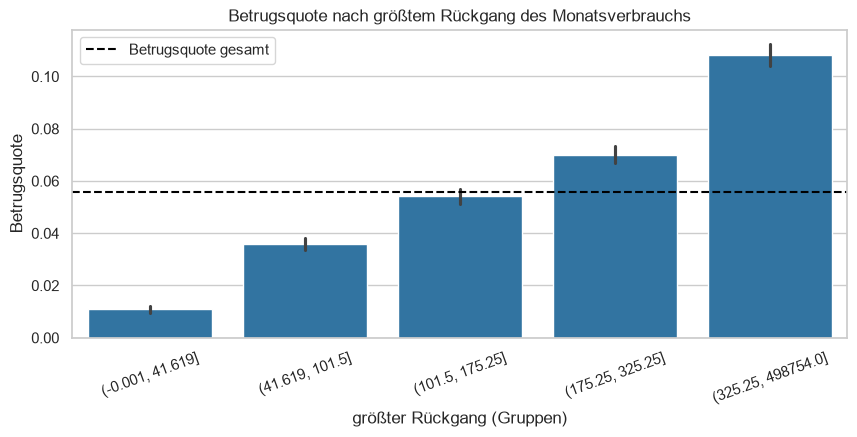

,count,mean
max_drop_gruppe,,
"(-0.001, 41.619]",21679,0.011
"(41.619, 101.5]",21715,0.036
"(101.5, 175.25]",21645,0.054
"(175.25, 325.25]",21684,0.070
"(325.25, 498754.0]",21671,0.108


In [7]:
train_ids = df_split.loc[df_split["split"] == "train", "client_id"]
df_check = df_features[df_features["client_id"].isin(train_ids)].copy()

korr = df_check[neue_spalten + ["target"]].corr(method="spearman")["target"].drop("target")
display(korr.sort_values(ascending=False).round(3))

# Betrugsquote nach größtem Rückgang
df_check["max_drop_gruppe"] = pd.qcut(df_check["max_drop"], q=5, duplicates="drop")

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=df_check, x="max_drop_gruppe", y="target", color="tab:blue", ax=ax)
ax.axhline(df_check["target"].mean(), color="black", linestyle="--", label="Betrugsquote gesamt")
ax.set_title("Betrugsquote nach größtem Rückgang des Monatsverbrauchs")
ax.set_xlabel("größter Rückgang (Gruppen)")
ax.set_ylabel("Betrugsquote")
ax.tick_params(axis="x", rotation=20)
ax.legend()
plt.show()

df_check.groupby("max_drop_gruppe", observed=True).agg(
    count=("target", "count"),
    mean=("target", "mean"),
).round(3)

Der größte Rückgang ist das stärkste neue Feature mit Spearman 0,15. Die Betrugsquote steigt von 1 % in der Gruppe mit den kleinsten Rückgängen auf 11 % in der mit den größten.

trend_ratio hat fast kein Signal, nur 0,02, meine Idee vom sinkenden Verbrauch stimmt also nicht. Was Code 8 bedeutet, weiß ich nicht, share_remarque_8 kommt auf 0,09.

In [8]:
df_features.to_csv(DATA_DIR / "fd_features.csv", index=False)
print(f"Gespeichert: {DATA_DIR / 'fd_features.csv'} ({df_features.shape[0]:,} Zeilen, {df_features.shape[1]} Spalten)")

Gespeichert: data/fd_features.csv (135,493 Zeilen, 33 Spalten)


fd_features.csv hat 33 Spalten, davon 13 neue. Die Datei liegt nicht auf GitHub. Ob die Features dem Modell helfen, sehe ich erst in 07_modelle.ipynb.